# Churn de actividad: Evaluacion final

Evalua el modelo seleccionado y el baseline en el mismo test. No utilizar este resultado para elegir hiperparametros.

**Estado:** ejecutado el 6 de octubre de 2026; resultados exploratorios revisados en README y docs/ejecuciones.md. Consulta ../docs/metodologia.md.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("activity_churn")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from activity_churn.alertas import configurar_notebook, mostrar_alertas
configurar_notebook()


# Evaluación final

Casos de test: **303**. El modelo **supera** el baseline en accuracy.

```text
          accuracy  average_precision   roc_auc
baseline  0.495050           0.504950  0.500000
modelo    0.772277           0.821799  0.837407
```

Las métricas describen esta partición. Revisar recall por clase y matriz de confusión en el JSON; no ajustar parámetros ni thresholds con este test. La definición del churn y la disponibilidad temporal de las features deben confirmarse en la fuente.

## Probabilidades y decisiones

Brier sigmoid **0.1678**, mayor que sin calibrar **0.1643**. Brier y log loss combinan calibración y discriminación; ECE depende de los bins. Las tablas de fiabilidad incluyen soporte y omiten bins vacíos. Con umbral fijado en validación **0.32**, se priorizan **227 de 303 casos**: recall **95.42%**, precisión **64.32%**, coste de error **0.383 unidades por caso**. FN=5.0, FP=1.0 son supuestos ilustrativos, no importes reales ni ahorro de retención. Se muestran todas las políticas sin elegir una nueva con test. ActivityChurn registra 185 IDs compartidos entre train y test; la independencia por persona sigue pendiente de confirmar.


,modelo,brier,log_loss,ece_10_bins
0,sin_calibrar,0.164339,0.499148,0.045271
1,sigmoid,0.167835,0.506233,0.081355


,politica,umbral,casos,priorizados,tp,fp,fn,tn,precision,recall,coste_error_total,coste_error_por_caso
0,sin_calibrar_05,0.50,303,166,125,41,28,109,0.753012,0.816993,181.0,0.597360
1,sigmoid_05,0.50,303,181,131,50,22,100,0.723757,0.856209,160.0,0.528053
2,umbral_validacion,0.32,303,227,146,81,7,69,0.643172,0.954248,116.0,0.382838
3,priorizar_todos,0.00,303,303,153,150,0,0,0.504950,1.000000,150.0,0.495050
4,priorizar_ninguno,1.00,303,0,0,0,153,150,0.000000,0.000000,765.0,2.524752


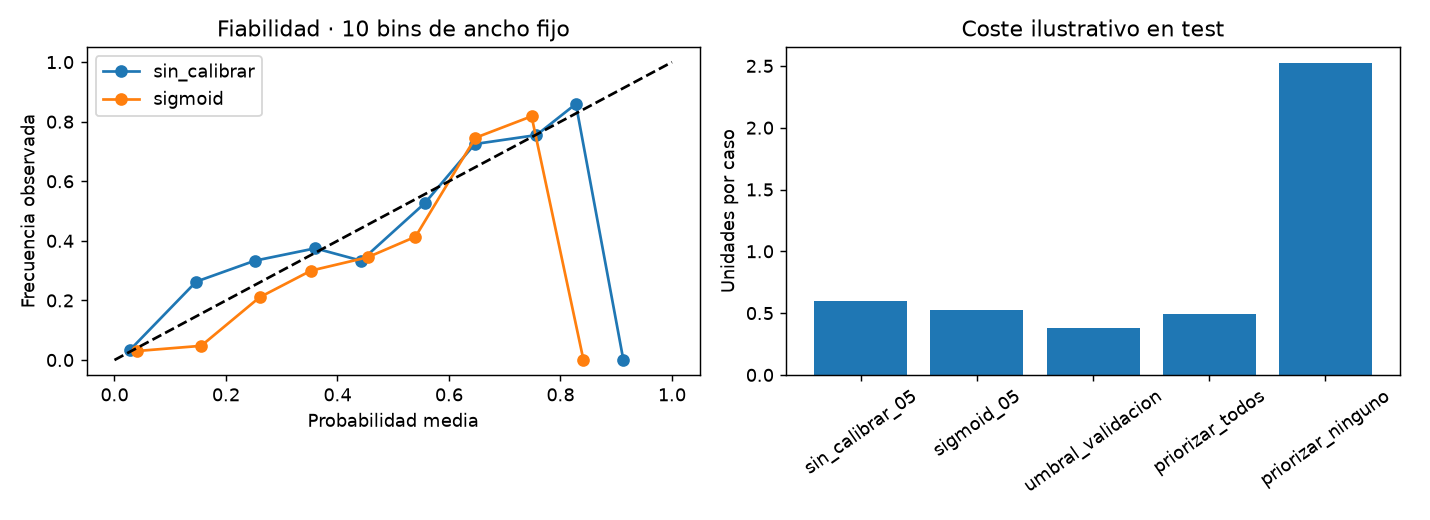

In [2]:
from activity_churn.flujo import evaluar
display(Markdown(evaluar(PROJECT_ROOT)))

from IPython.display import Image
import pandas as pd
display(pd.read_csv(PROJECT_ROOT/"reports/evaluacion/calibracion_test.csv"))
display(pd.read_csv(PROJECT_ROOT/"reports/evaluacion/politicas_test.csv"))
display(Image(filename=str(PROJECT_ROOT/"reports/evaluacion/decisiones.png")))

## Alertas de la ejecucion

Avisos agrupados con descripcion generica, acciones sugeridas y detalle original. Los errores de celda no se ocultan.

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from activity_churn.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/Analisis/churn/ActivityChurn/reports/informe_final/informe_final.md')